In [1]:
import os
import pickle
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import make_classification
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "\npandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.14.5
NumPy: 2.5.4 
pandas: 3.0.6
scikit-learn: 1.9.1


In [2]:
dataset_split = 'val'
sub_folder = '/og_params' # use empty string if not using

In [3]:
from GTZANClassifier import GTZANClassifier

feat_types = ['full', 'mfcc'] # , 'spectral'
rng_states = ['42', '351', '605'] # , '351', '605'
time_states = ['30'] # '3', 

classifers = {}

for t in time_states:
    for feat in feat_types:
        for rng in rng_states:
            name = f'{t}s_{feat}_rng{rng}'
            classifers[name] = GTZANClassifier()
            classifers[name].load_models(
                pkl_filepath=f'./trained_models{sub_folder}/{name}.pkl',
                data_dirpath=f'./GTZAN/Data_filtered/{t}s_split/')

Loading TRAIN split from: train_filtered_30s_features.csv
Dataset 'GTZAN\Data_filtered\30s_split\train_filtered_30s_features.csv' has 0 missing entries.
Feature Subset: Full feature set.
Loading TEST split from: test_filtered_30s_features.csv
Dataset 'GTZAN\Data_filtered\30s_split\test_filtered_30s_features.csv' has 0 missing entries.
Feature Subset: Full feature set.
Loading VAL split from: valid_filtered_30s_features.csv
Dataset 'GTZAN\Data_filtered\30s_split\valid_filtered_30s_features.csv' has 0 missing entries.
Feature Subset: Full feature set.
Train size: 463 | Val size: 203 | Test size: 300
-> Data splits successfully reconstructed for '30s_full_rng42'.
Models successfully loaded from './trained_models/og_params/30s_full_rng42.pkl'.

Loading TRAIN split from: train_filtered_30s_features.csv
Dataset 'GTZAN\Data_filtered\30s_split\train_filtered_30s_features.csv' has 0 missing entries.
Feature Subset: Full feature set.
Loading TEST split from: test_filtered_30s_features.csv
Datase

In [4]:
classifers['30s_full_rng42']

In [5]:
# classifers['3s_full_rng605'].find_best_k()
# classifers['3s_full_rng605'].train_baseline_models()

In [6]:
classifers['30s_mfcc_rng42'].models['KNN']['metrics'].keys()

dict_keys(['train', 'val', 'test'])

In [7]:

master_records = []

for config_name, clf in classifers.items():
    # 1. Get file-level storage footprint from disk
    pkl_path = f'./trained_models/{config_name}.pkl'
    file_size_kb = os.path.getsize(pkl_path) / 1024 if os.path.exists(pkl_path) else 0
    
    # 2. Parse variant and feature subset from config name
    parts = config_name.split('_')
    dataset_variant = parts[0] # " # e.g., '3_sec' or '30_sec'
    feature_subset = parts[1]        # e.g., 'full', 'mfcc', 'spectral'
    rng_state = parts[2][3:]

    # 3. Loop through each model trained within this configuration
    for model_name, model_dict in clf.models.items():
        if 'metrics' not in model_dict:
            continue
            
        m = model_dict['metrics'][dataset_split]
        m_train = model_dict['training metrics']
        
        # FIXED: Use pickle.dumps() to calculate the in-memory size
        model_bytes = pickle.dumps(model_dict['model'])
        model_memory_kb = len(model_bytes) / 1024

        master_records.append({
            'Dataset': dataset_variant,
            'Features': feature_subset,
            'rng State': rng_state,
            'Configuration': config_name,
            'Model': model_name,
            'Test Balanced Accuracy': 1.0 - m_train['test_error'],
            'Macro F1-Score': m.get('f1_score', 0),
            'Precision' : m['precision'],
            'Recall' : m['recall'],
            'Train Time (s)': m_train.get('training_time_seconds', 0),
            'Model Memory (KB)': model_memory_kb,
            'File Size (KB)': file_size_kb
        })

df_master = pd.DataFrame(master_records)

# Sort by Test Accuracy descending
# Sort by Macro F1-Score first, then Test Accuracy as a tie-breaker
df_master = df_master.sort_values(by=['Test Balanced Accuracy', 'Macro F1-Score'], ascending=False).reset_index(drop=True)
print("\n--- MASTER PERFORMANCE & RESOURCE COMPARISON ---")
print(df_master.to_string(index=False))



--- MASTER PERFORMANCE & RESOURCE COMPARISON ---
Dataset Features rng State   Configuration                          Model  Test Balanced Accuracy  Macro F1-Score  Precision   Recall  Train Time (s)  Model Memory (KB)  File Size (KB)
    30s     full       605 30s_full_rng605 Tuned Ensemble (SVM + RF + GB)                0.525219        0.396520   0.451153 0.418773       42.744294       12975.117188     5875.231445
    30s     full       605 30s_full_rng605                      SVM (RBF)                0.521284        0.370146   0.402239 0.393627        0.079366         243.358398     5875.231445
    30s     mfcc       351 30s_mfcc_rng351 Tuned Ensemble (SVM + RF + GB)                0.520436        0.349783   0.365600 0.376245       44.628085        9719.463867     2268.825195
    30s     full        42  30s_full_rng42                      SVM (RBF)                0.520202        0.378266   0.416418 0.408971        0.113948         253.393555     5883.105469
    30s     full       35

In [8]:
def get_total_master_memory(df_master, unit='KB'):
    """
    Loops through the master DataFrame and calculates the total memory footprint 
    of all stored models using the preexisting 'Model Memory (KB)' column.
    
    Parameters:
    -----------
    df_master : pd.DataFrame
        The master records DataFrame containing 'Model Memory (KB)'.
    unit : str
        The desired output unit: 'KB' or 'MB'.
        
    Returns:
    --------
    float
        The total accumulated memory size.
    """
    if 'Model Memory (KB)' not in df_master.columns:
        print("Error: 'Model Memory (KB)' column not found in DataFrame.")
        return 0.0

    # Sum up all model memory entries in KB
    total_kb = df_master['Model Memory (KB)'].sum()
    
    if unit.upper() == 'MB':
        total_value = total_kb / 1024
        unit_label = 'MB'
    else:
        total_value = total_kb
        unit_label = 'KB'
        
    print(f"\n--- TOTAL MASTER MEMORY REPORT ---")
    print(f"Total entries evaluated: {len(df_master)}")
    print(f"Total model memory footprint: {total_value:.2f} {unit_label}")
    print("=" * 34 + "\n")
    
    return total_value

get_total_master_memory(df_master, unit='MB')


--- TOTAL MASTER MEMORY REPORT ---
Total entries evaluated: 42
Total model memory footprint: 108.57 MB



np.float64(108.56963539123535)

In [9]:

# Print Best Overall Model
best_row = df_master.iloc[0]
print(f"\nBest Overall Model:")
print(f"  • Configuration: {best_row['Configuration']}")
print(f"  • Model Type: {best_row['Model']}")
print(f"  • Test Accuracy: {best_row['Test Balanced Accuracy']:.4f}")
print(f"  • Macro F1-Score: {best_row['Macro F1-Score']:.4f}")


Best Overall Model:
  • Configuration: 30s_full_rng605
  • Model Type: Tuned Ensemble (SVM + RF + GB)
  • Test Accuracy: 0.5252
  • Macro F1-Score: 0.3965


In [10]:
# df_pivot = df_master.pivot(index='Configuration', columns='Model', values='Test Accuracy')
# fig, ax = plt.subplots(figsize=(12, 6))
# df_pivot.plot(kind='bar', ax=ax, width=0.8, colormap='tab10')
# ax.set_title('Test Accuracy Comparison Across All Configurations and Models', fontsize=14)
# ax.set_xlabel('Dataset & Feature Configuration', fontsize=12)
# ax.set_ylabel('Test Accuracy', fontsize=12)
# ax.set_ylim(0, 1.0)
# plt.xticks(rotation=30, ha='right')
# ax.grid(axis='y', linestyle='--', alpha=0.7)
# ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

# plt.tight_layout()
# plt.show() 

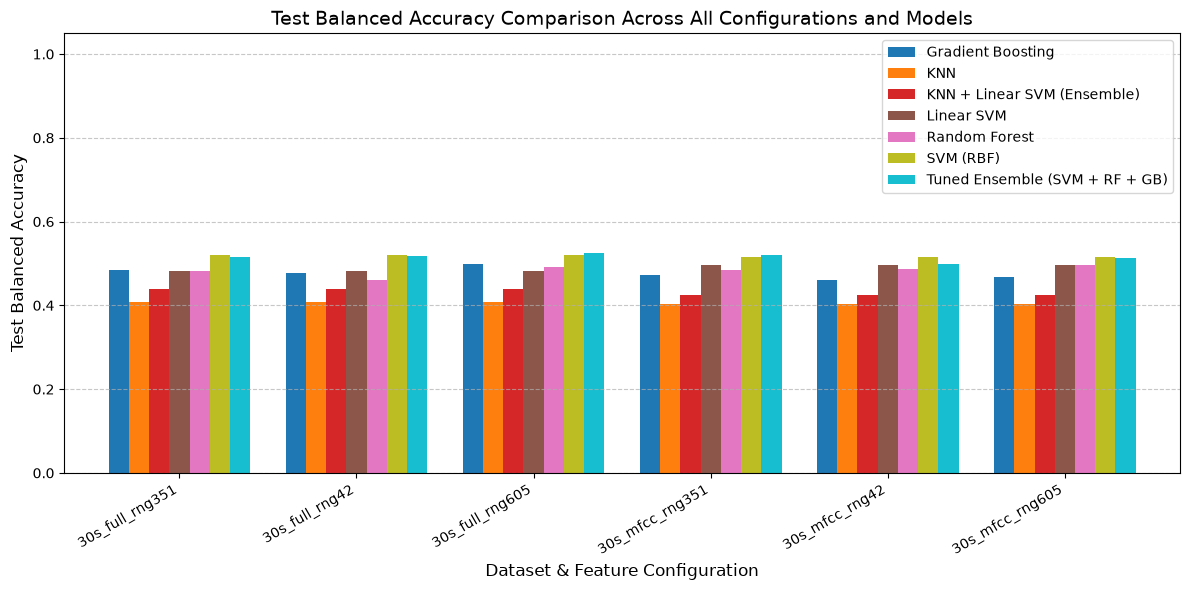

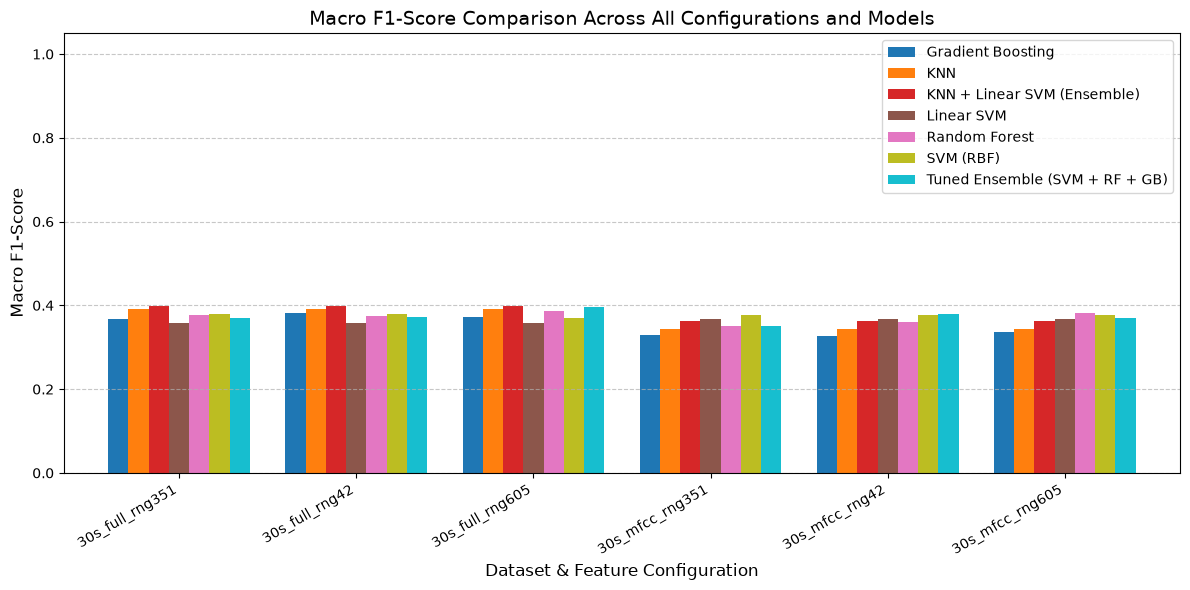

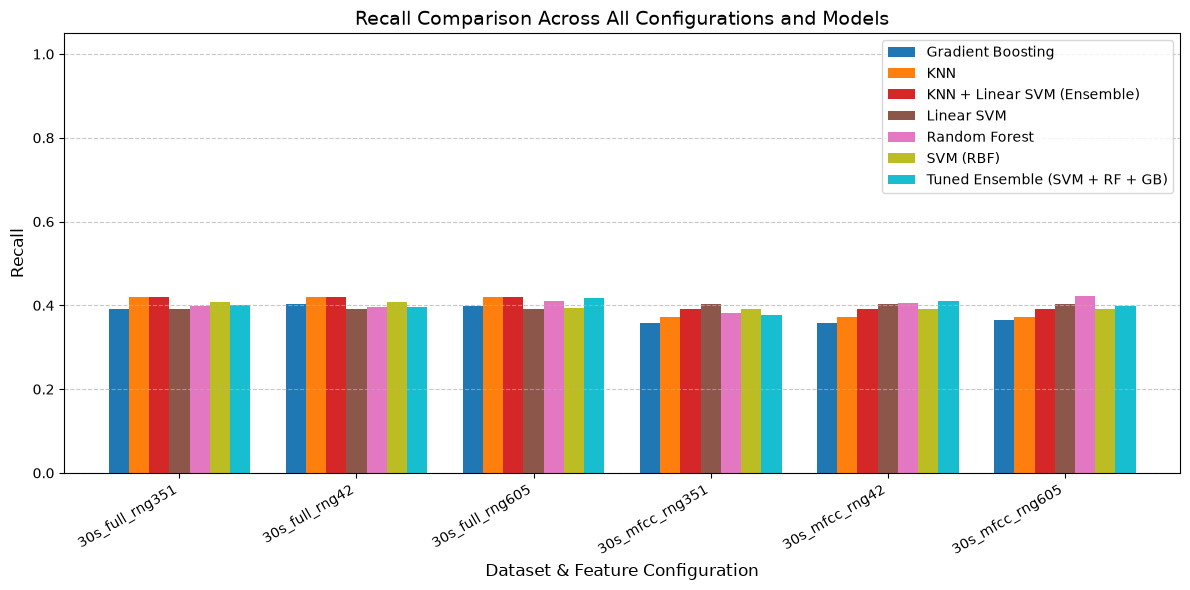

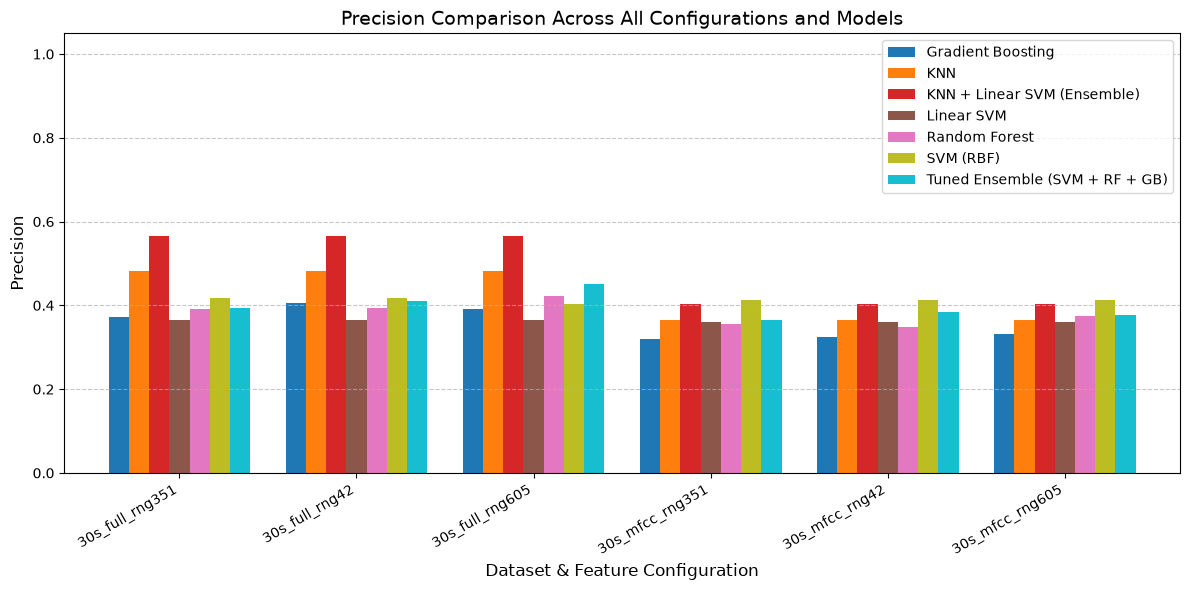

(<Figure size 1200x600 with 1 Axes>,
 <Axes: title={'center': 'Precision Comparison Across All Configurations and Models'}, xlabel='Dataset & Feature Configuration', ylabel='Precision'>)

In [11]:
def plot_metric_comparison(df_master, metric='Macro F1-Score'):
    """
    Plots a grouped bar chart comparing all models across configurations 
    for any specified metric found in df_master.
    """
    # Pivot data so models become columns and configurations become rows
    df_pivot = df_master.pivot(index='Configuration', columns='Model', values=metric)

    fig, ax = plt.subplots(figsize=(12, 6))
    df_pivot.plot(kind='bar', ax=ax, width=0.8, colormap='tab10')

    ax.set_title(f'{metric} Comparison Across All Configurations and Models', fontsize=14)
    ax.set_xlabel('Dataset & Feature Configuration', fontsize=12)
    ax.set_ylabel(metric, fontsize=12)
    
    # Set y-limits automatically based on metric type (probabilities/scores vs time/memory)
    if 'Error' in metric or 'Accuracy' in metric or (
            'F1' in metric or 'Precision' in metric or 'Recall' in metric):
        ax.set_ylim(0, 1.05)
        
    plt.xticks(rotation=30, ha='right')
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.legend(loc='best')

    plt.tight_layout()
    plt.show()
    return fig, ax

plot_metric_comparison(df_master, metric='Test Balanced Accuracy')
plot_metric_comparison(df_master, metric='Macro F1-Score')
plot_metric_comparison(df_master, metric='Recall')
plot_metric_comparison(df_master, metric='Precision')

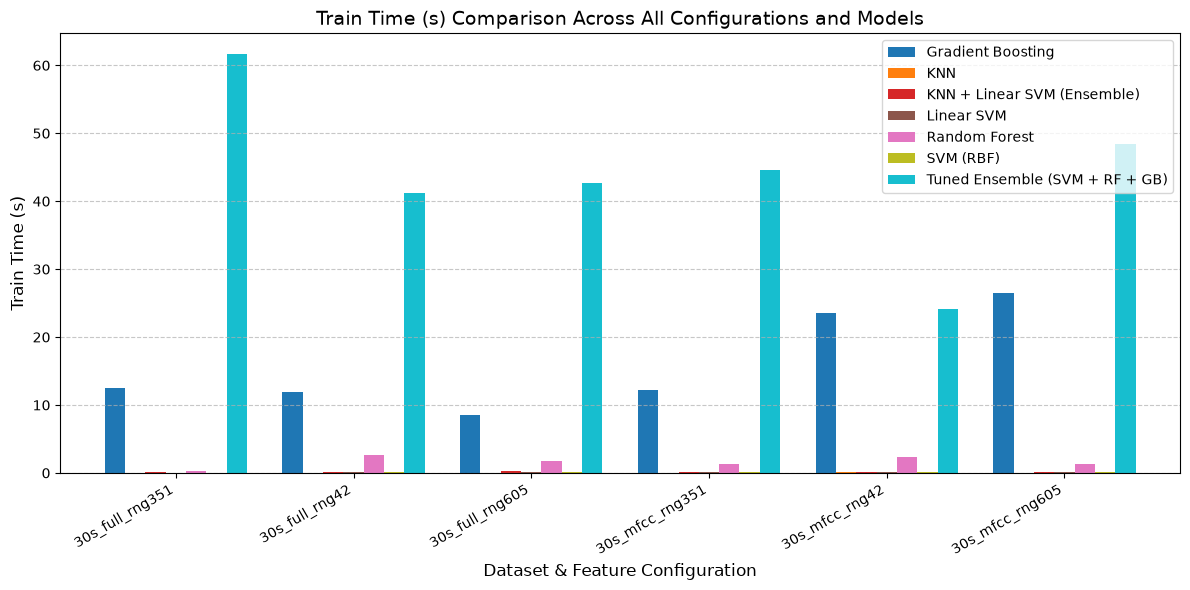

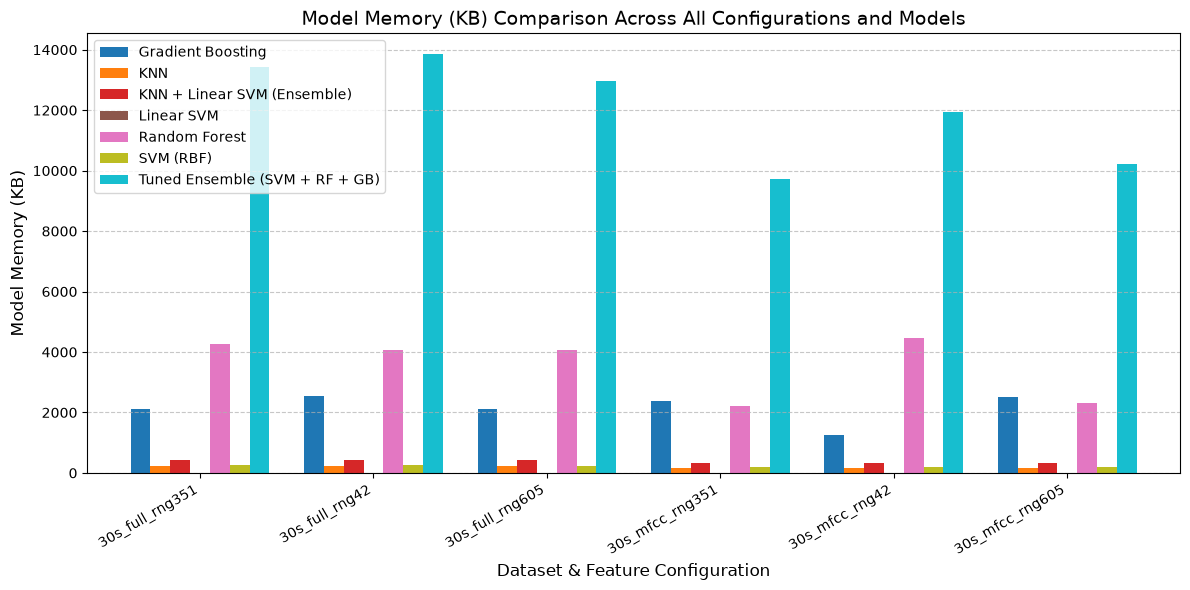

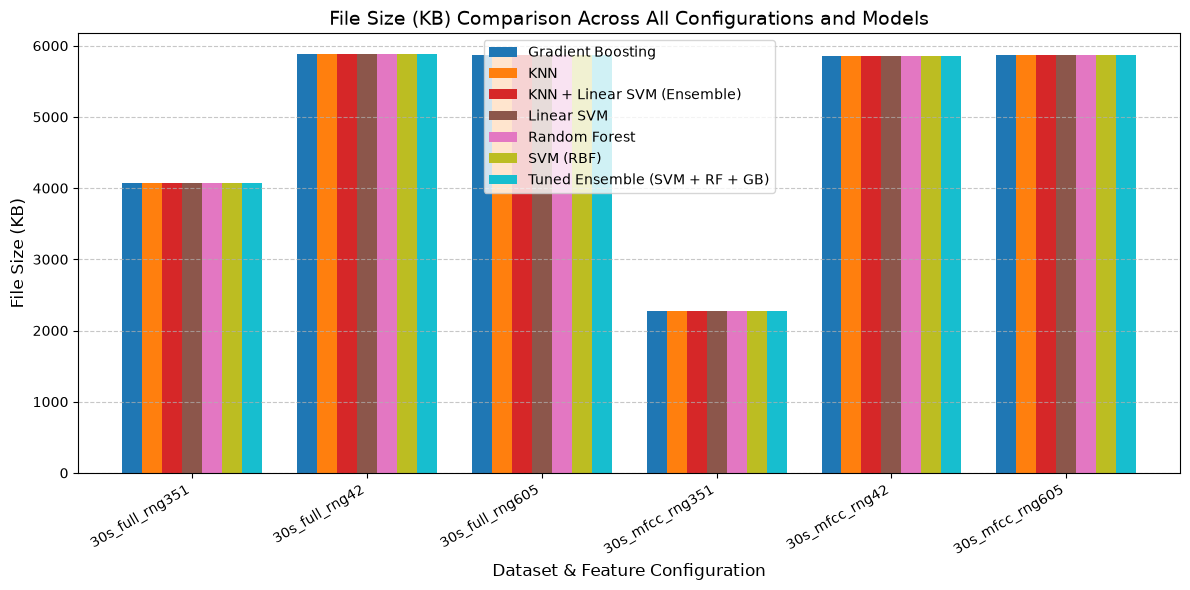

(<Figure size 1200x600 with 1 Axes>,
 <Axes: title={'center': 'File Size (KB) Comparison Across All Configurations and Models'}, xlabel='Dataset & Feature Configuration', ylabel='File Size (KB)'>)

In [12]:
plot_metric_comparison(df_master, metric='Train Time (s)')
plot_metric_comparison(df_master, metric='Model Memory (KB)')
plot_metric_comparison(df_master, metric='File Size (KB)')

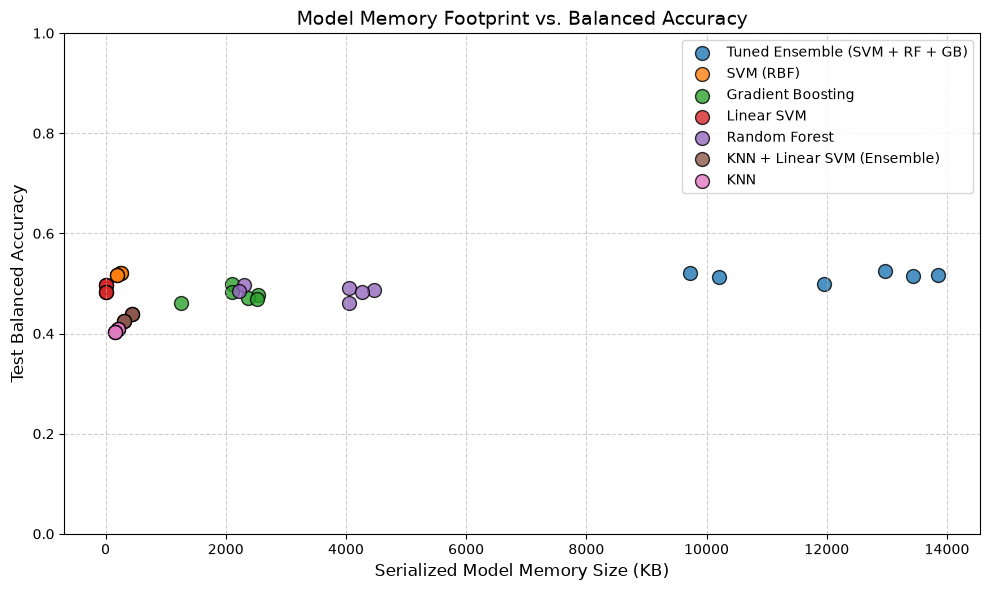

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))

# Define colors/markers manually or let matplotlib cycle through them
models_list = df_master['Model'].unique()
colors = plt.cm.tab10.colors

for i, model_name in enumerate(models_list):
    subset = df_master[df_master['Model'] == model_name]
    ax.scatter(
        subset['Model Memory (KB)'],
        subset['Test Balanced Accuracy'],
        label=model_name,
        color=colors[i % len(colors)],
        s=100,
        alpha=0.8,
        edgecolors='k'
    )

ax.set_title('Model Memory Footprint vs. Balanced Accuracy', fontsize=14)
# ax.set_xscale('log')
ax.set_xlabel('Serialized Model Memory Size (KB)', fontsize=12)
ax.set_ylabel('Test Balanced Accuracy', fontsize=12)
ax.set_ylim(0, 1.0)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='best')

plt.tight_layout()
plt.show()

In [14]:
def plot_per_class_heatmap(classifiers_dict, metric_key='f1_score_per_class', target_model='SVM (RBF)'):
    """
    Creates a heatmap showing per-class scores.
    - If target_model is a specific name (e.g., 'SVM (RBF)' - default), compares all configs for that model.
    - If target_model='ALL', compares every model across every configuration.
    
    metric_key options: 'precision_per_class', 'recall_per_class', 'f1_score_per_class'
    """
    matrix_data = []
    config_labels = []
    genre_labels = None

    for config_name, clf in classifiers_dict.items():
        # Determine which models to evaluate for this configuration
        if str(target_model).upper() == 'ALL':
            models_to_process = list(clf.models.keys())
        else:
            # Check if the requested target model exists in this configuration
            models_to_process = [target_model] if target_model in clf.models else []

        for model_name in models_to_process:
            model_dict = clf.models.get(model_name)
            if model_dict and 'metrics' in model_dict and metric_key in model_dict['metrics'][dataset_split]:
                matrix_data.append(model_dict['metrics'][dataset_split][metric_key])
                config_labels.append(f"{config_name} | {model_name}")
                if genre_labels is None:
                    genre_labels = clf.labels

    if not matrix_data:
        print(f"No per-class metrics found for target_model='{target_model}'.")
        return None, None

    matrix = np.array(matrix_data) # Shape: (rows, genres)

    # Automatically scale figure height based on how many rows we are displaying
    fig, ax = plt.subplots(figsize=(10, max(4, len(config_labels) * 0.45)))
    im = ax.imshow(matrix, cmap='YlGnBu', vmin=0.0, vmax=1.0)

    # Configure axes
    ax.set_xticks(np.arange(len(genre_labels)))
    ax.set_yticks(np.arange(len(config_labels)))
    ax.set_xticklabels(genre_labels, rotation=45, ha="right")
    ax.set_yticklabels(config_labels, fontsize=9)

    # Add text annotations inside heatmap blocks for readability
    for i in range(len(config_labels)):
        for j in range(len(genre_labels)):
            val = matrix[i, j]
            text_color = "white" if val > 0.6 else "black"
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=text_color, fontsize=8)

    title_suffix = f"({target_model})" if str(target_model).upper() != 'ALL' else "(All Models & Configs)"
    metric_title = metric_key.replace('_per_class', '').replace('_', ' ').upper()
    
    ax.set_title(f"Per-Class Performance Heatmap {title_suffix}\n[{metric_title}]", fontsize=14, pad=15)
    ax.set_xlabel("GTZAN Genre Classes", fontsize=12)
    ax.set_ylabel("Configuration & Model", fontsize=12)

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()
    return fig, ax

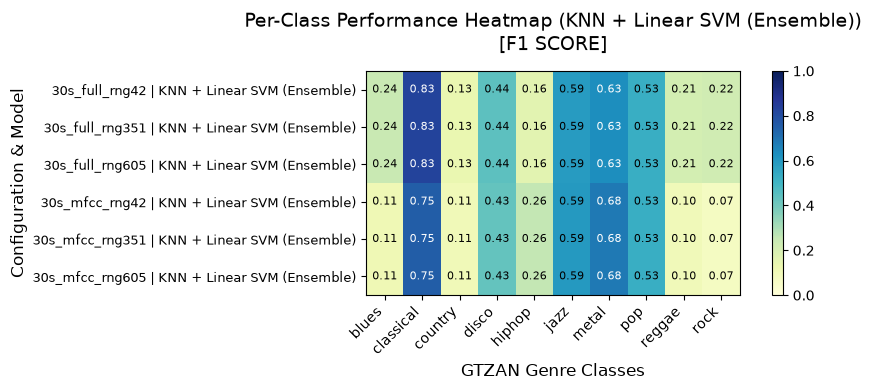

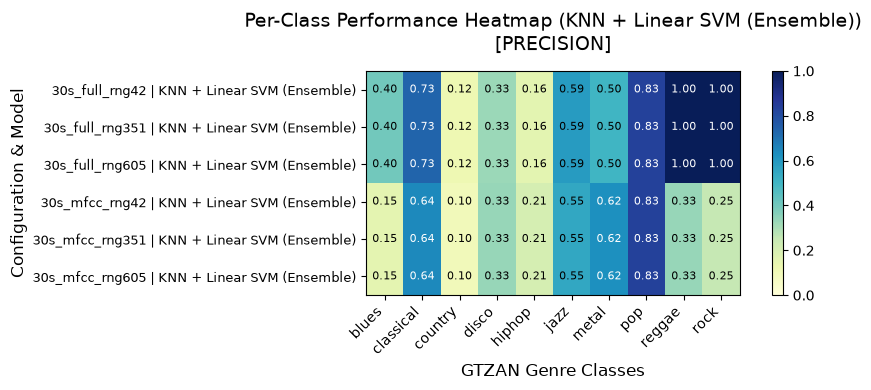

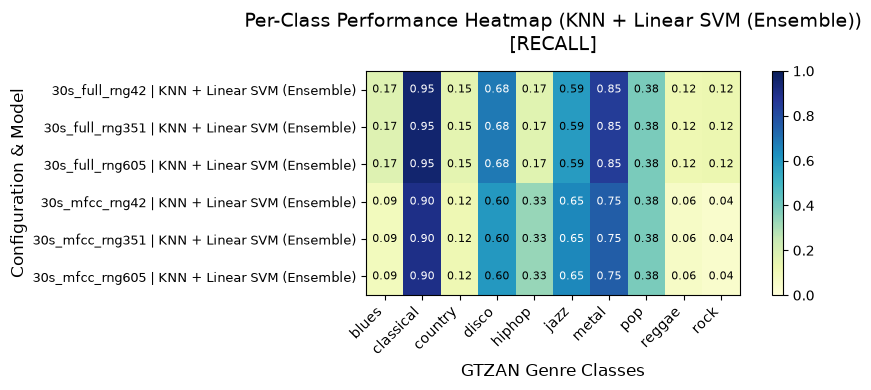

(<Figure size 1000x400 with 2 Axes>,
 <Axes: title={'center': 'Per-Class Performance Heatmap (KNN + Linear SVM (Ensemble))\n[RECALL]'}, xlabel='GTZAN Genre Classes', ylabel='Configuration & Model'>)

In [15]:
baseline_model = 'KNN + Linear SVM (Ensemble)'
plot_per_class_heatmap(
    classifers, metric_key='f1_score_per_class',target_model=baseline_model)
plot_per_class_heatmap(
    classifers, metric_key='precision_per_class',target_model=baseline_model)
plot_per_class_heatmap(
    classifers, metric_key='recall_per_class',target_model=baseline_model)

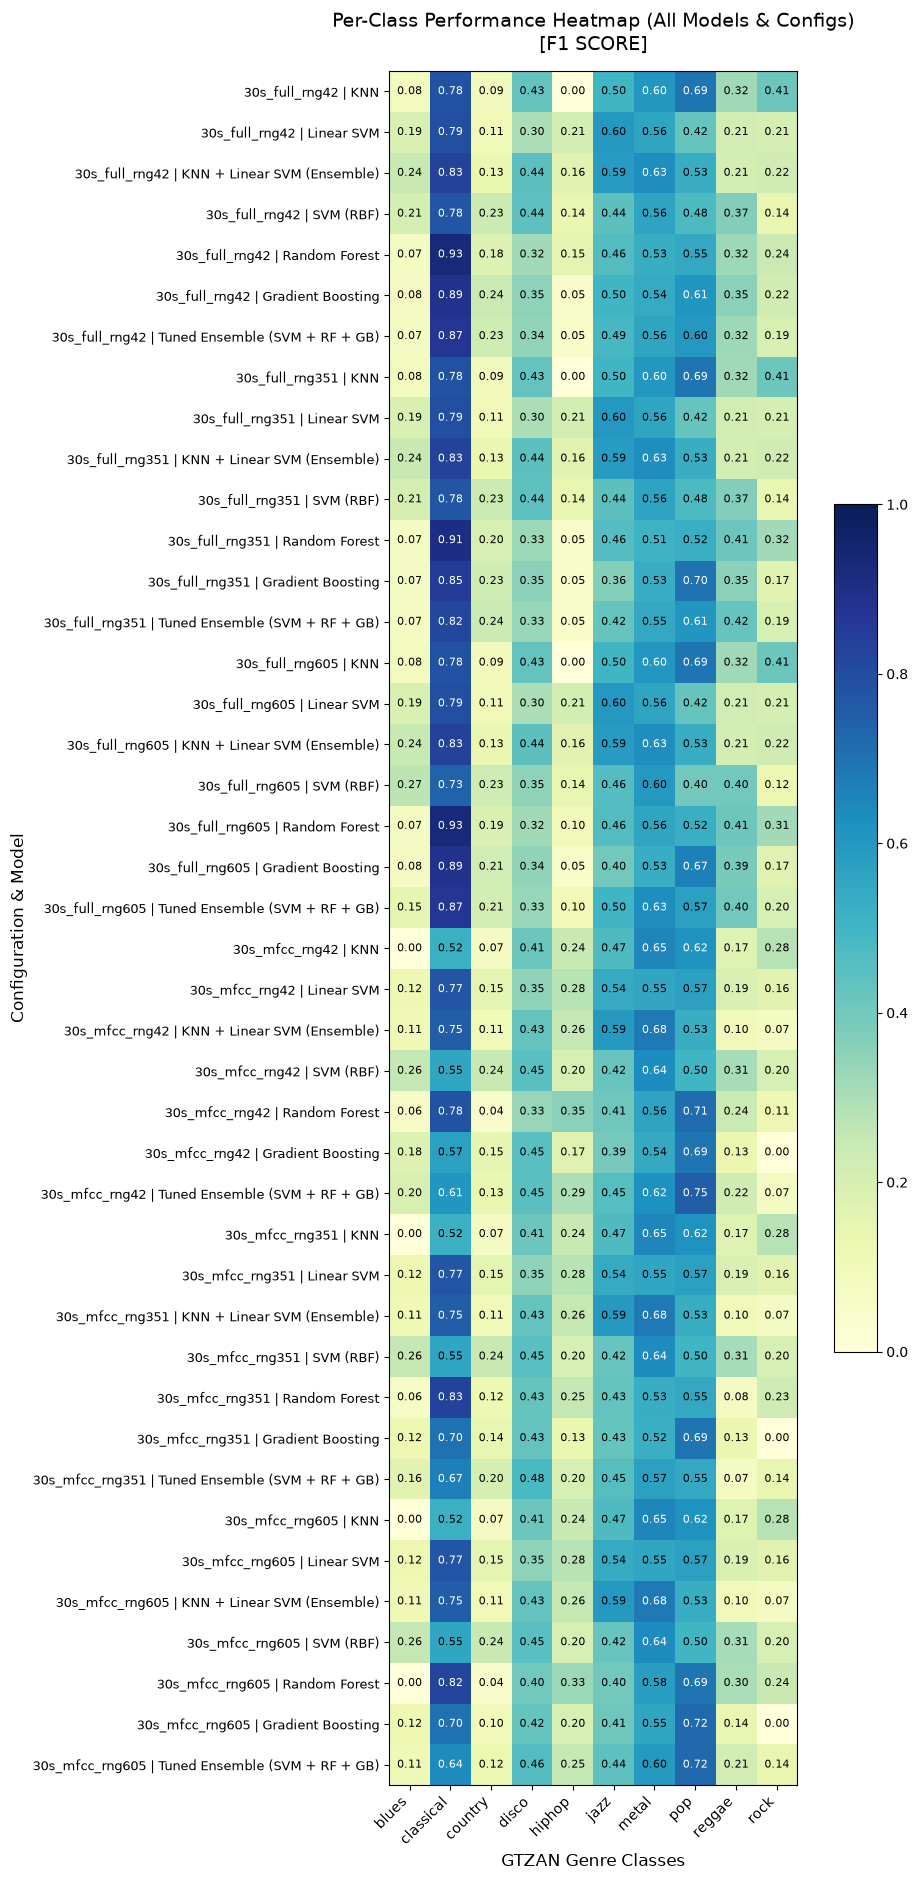

(<Figure size 1000x1890 with 2 Axes>,
 <Axes: title={'center': 'Per-Class Performance Heatmap (All Models & Configs)\n[F1 SCORE]'}, xlabel='GTZAN Genre Classes', ylabel='Configuration & Model'>)

In [16]:
plot_per_class_heatmap(
    classifers, metric_key='f1_score_per_class', target_model='ALL')

Top 4 Models Across All Configurations:
1. [30s_mfcc_rng605] Random Forest | F1: 0.3808 | Acc: 0.4225
2. [30s_full_rng42] KNN | F1: 0.3910 | Acc: 0.4208
3. [30s_full_rng351] KNN | F1: 0.3910 | Acc: 0.4208
4. [30s_full_rng605] KNN | F1: 0.3910 | Acc: 0.4208


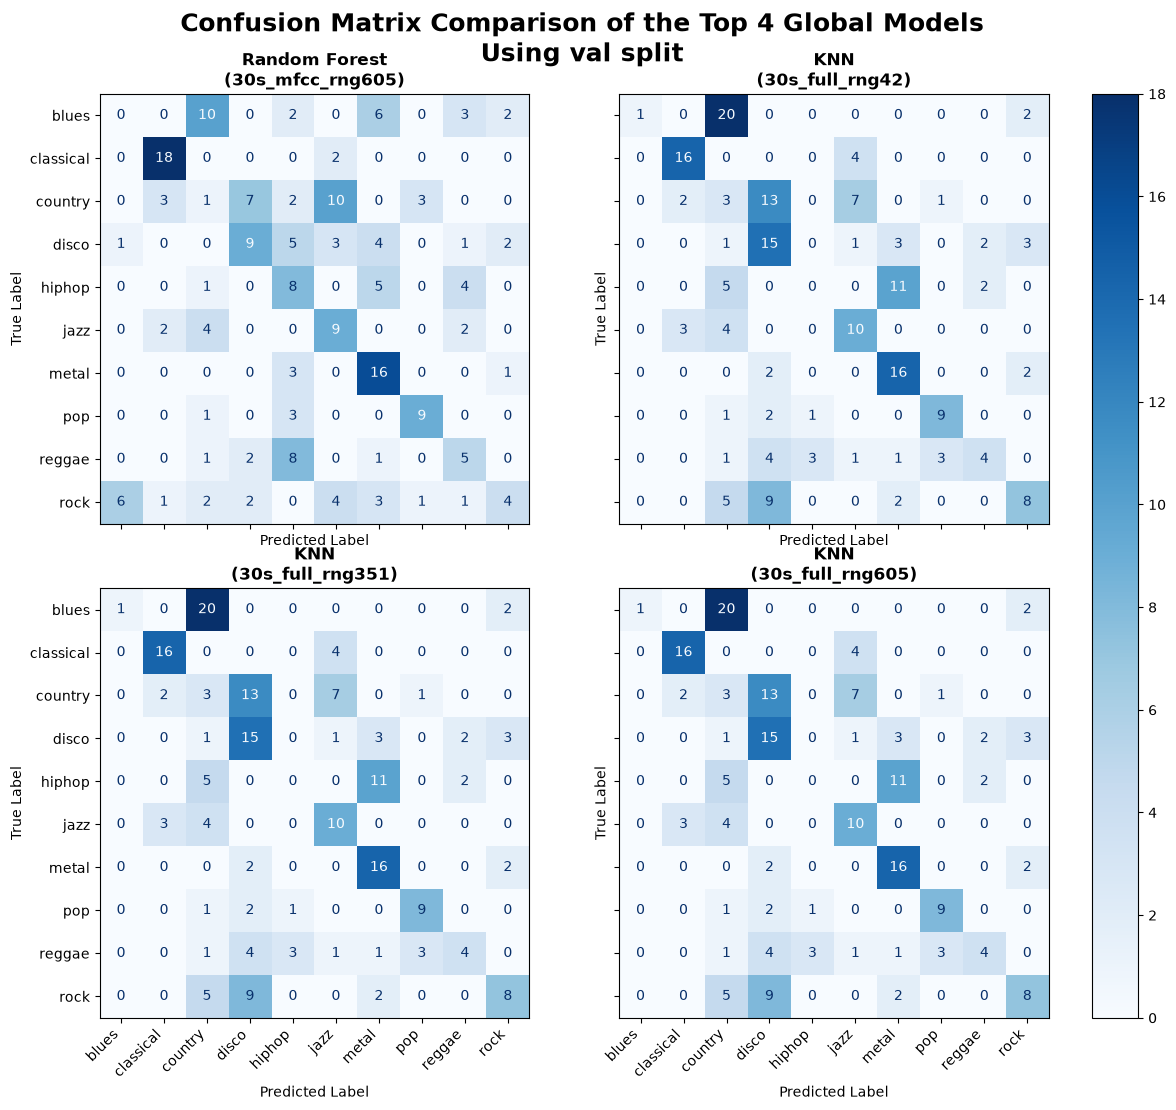

In [17]:
# 1. Gather all individual model records across every configuration file into a master list
all_models_pool = []

# y_true = classifers['30_sec_full'].y_test

for config_name, clf in classifers.items():
    for model_name, model_dict in clf.models.items():
        if 'metrics' not in model_dict:
            continue
        
        m = model_dict['metrics'][dataset_split]
        all_models_pool.append({
            'config_name': config_name,
            'model_name': model_name,
            'classifier_obj': clf,             # Reference to the specific GTZAN instance (holds y_test, gtzan_labels)
            'model_dict': model_dict,
            'test_accuracy': m.get('bal_accuracy',0),
            'macro_f1': m.get('f1_score', 0)
        })

# 2. Convert to DataFrame and sort to find the top 4 models overall 
# (using Macro F1 and Test Accuracy to ensure high quality)
df_pool = pd.DataFrame(all_models_pool)
df_top4 = df_pool.sort_values(by=['test_accuracy', 'macro_f1'], ascending=False).head(4).reset_index(drop=True)

print("Top 4 Models Across All Configurations:")
for idx, row in df_top4.iterrows():
    print(f"{idx+1}. [{row['config_name']}] {row['model_name']} | F1: {row['macro_f1']:.4f} | Acc: {row['test_accuracy']:.4f}")

# 3. Plot the Confusion Matrices for these Top 4 models in a single 2x2 figure
fig, axes = plt.subplots(
    2, 2, figsize=(14, 12),
    sharex=True, sharey=True,
    gridspec_kw={'hspace': 0.15, 'wspace': 0.1}
)
axes_flat = axes.ravel()
im1 = None

for i, row in df_top4.iterrows():
    ax = axes_flat[i]
    clf = row['classifier_obj']
    m_name = row['model_name']
    c_name = row['config_name']

    _,_,y_true, X_to_use = clf._parse_dataset_type(dataset_split)
    y_pred = clf.predict(X_to_use,target_model=m_name)
    
    # Generate confusion matrix display using true labels from that model's respective dataset split
    disp = ConfusionMatrixDisplay.from_predictions(
        y_true, 
        y_pred, 
        display_labels=clf.labels,  
        cmap=plt.cm.Blues,
        ax=ax,
        colorbar=False
    )
    
    # Clear and descriptive title including its source configuration
    ax.set_title(f"{m_name}\n({c_name})", fontsize=12, fontweight='bold')
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_ylabel("True Label", fontsize=10)
    ax.set_xlabel("Predicted Label", fontsize=10)
    
    if i == 0:
        im1 = disp.im_

# Add a clean unified colorbar for the entire 2x2 grid without clipping
fig.colorbar(
    im1, ax=axes_flat,
    fraction=0.046, pad=0.04
)

fig.suptitle(
    "Confusion Matrix Comparison of the Top 4 Global Models" +
    f"\nUsing {dataset_split} split",
    fontsize=18, y=0.95, fontweight='bold'
)
plt.show()

In [18]:
def look_at_summary(dataset, model):
    print(f'\n{dataset}')
    print(classifers[dataset].models[model]['metrics'][dataset_split]['classification_report'])
look_at_summary('30s_mfcc_rng42', model=baseline_model)
# look_at_summary('30s_full_rng42', model=baseline_model)


30s_mfcc_rng42
              precision    recall  f1-score   support

       blues       0.15      0.09      0.11        23
   classical       0.64      0.90      0.75        20
     country       0.10      0.12      0.11        26
       disco       0.33      0.60      0.43        25
      hiphop       0.21      0.33      0.26        18
        jazz       0.55      0.65      0.59        17
       metal       0.62      0.75      0.68        20
         pop       0.83      0.38      0.53        13
      reggae       0.33      0.06      0.10        17
        rock       0.25      0.04      0.07        24

    accuracy                           0.38       203
   macro avg       0.40      0.39      0.36       203
weighted avg       0.37      0.38      0.34       203



In [19]:
def display_confusion_matrix(model, name, labels=None, title="Confusion Matrix"):
    """
    Displays a confusion matrix using ConfusionMatrixDisplay.
    """
    cm = model[name]

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, 
        display_labels=labels
    )
    
    fig, ax = plt.subplots(figsize=(8, 6))
    disp.plot(
        cmap=plt.cm.Blues, 
        ax=ax, 
        colorbar=True,
        values_format='d'  # Use 'd' for integers, or '.2f' for normalized/percentages
    )
    
    ax.set_title(title, fontsize=14)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
    
    return fig, ax

# display_confusion_matrix

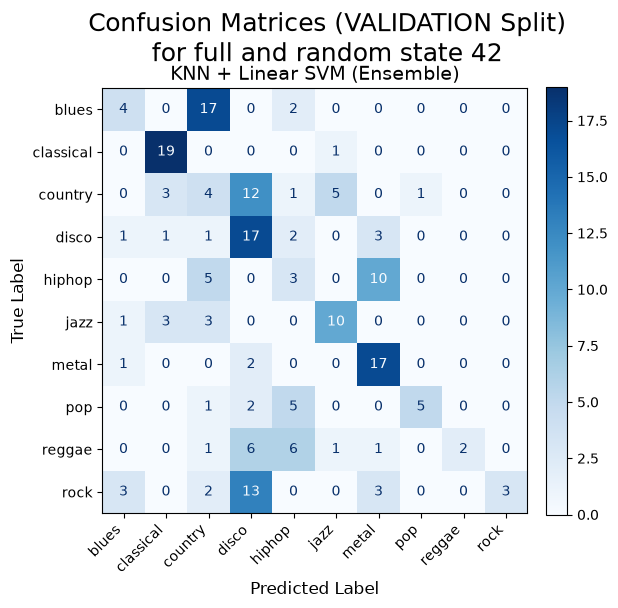

(<Figure size 600x600 with 2 Axes>,
 <Axes: title={'center': 'KNN + Linear SVM (Ensemble)'}, xlabel='Predicted Label', ylabel='True Label'>)

In [20]:
classifers['30s_full_rng42'].plot_confusion_matrices(
    model_names=baseline_model, data_split='val', displayPlot=True)

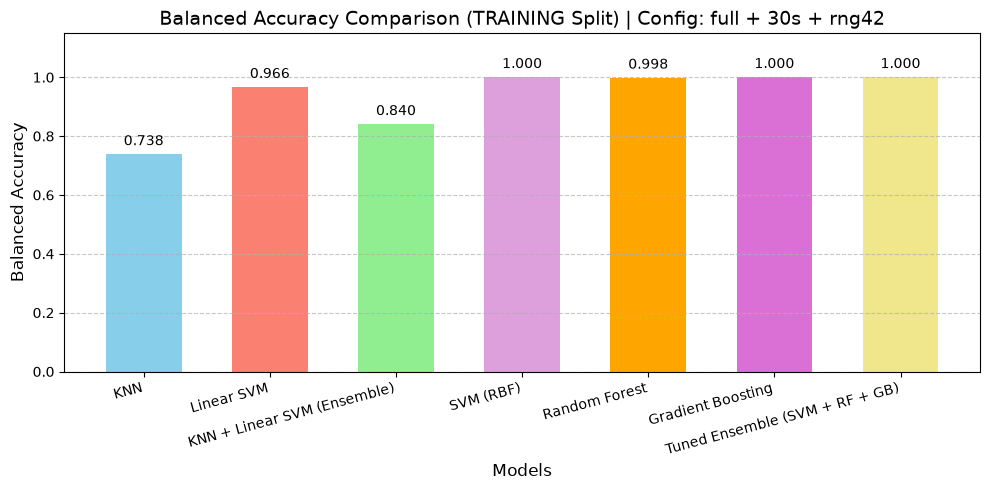

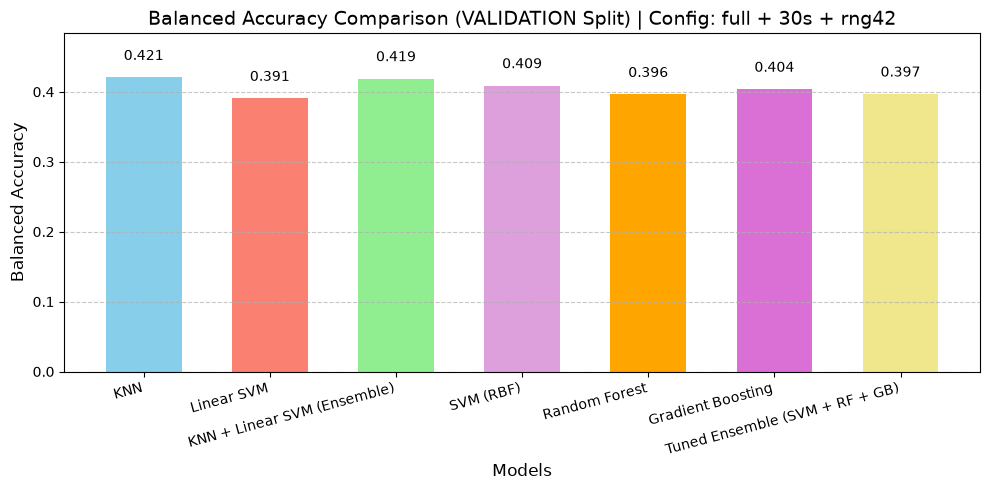

(<Figure size 1000x500 with 1 Axes>,
 <Axes: title={'center': 'Balanced Accuracy Comparison (VALIDATION Split) | Config: full + 30s + rng42'}, xlabel='Models', ylabel='Balanced Accuracy'>)

In [21]:
classifers['30s_full_rng42'].plot_metric_comparison(
    metric='Balanced Accuracy', data_split='train', displayPlot=True)
classifers['30s_full_rng42'].plot_metric_comparison(
    metric='Balanced Accuracy', data_split='val', displayPlot=True)

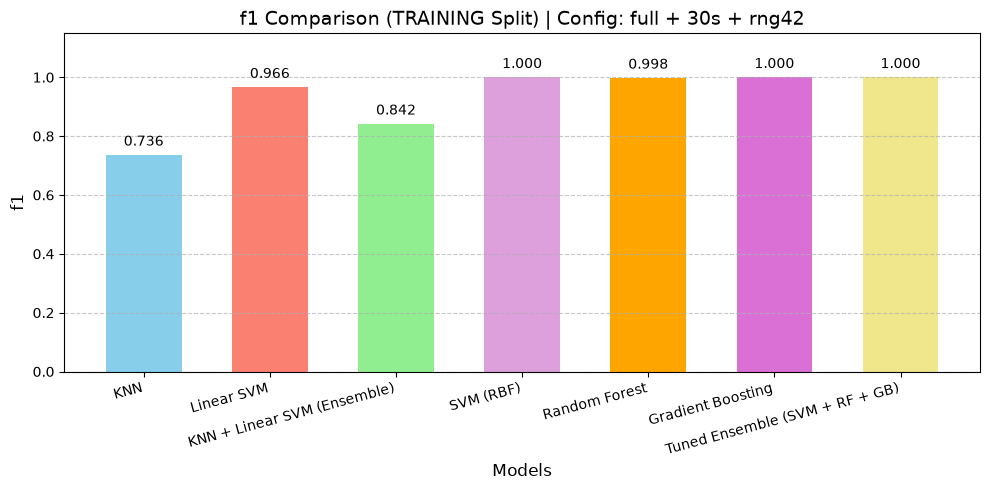

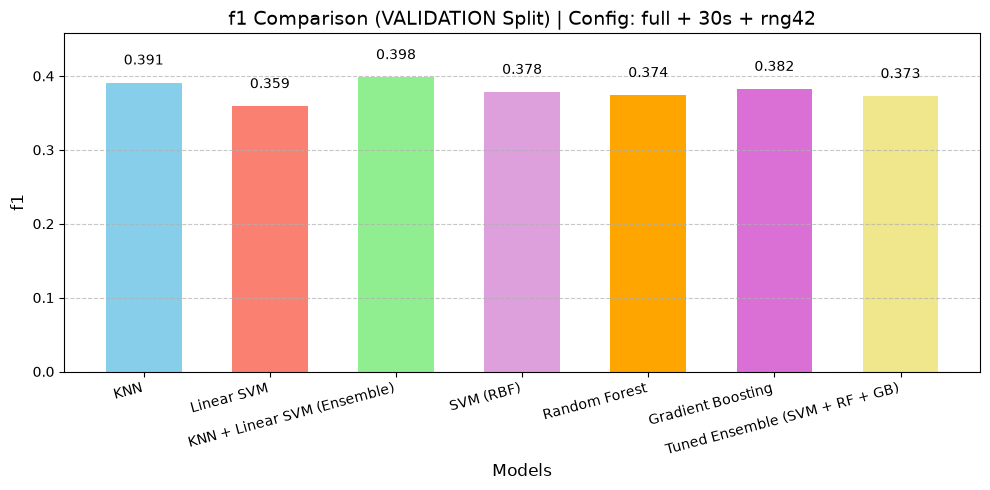

(<Figure size 1000x500 with 1 Axes>,
 <Axes: title={'center': 'f1 Comparison (VALIDATION Split) | Config: full + 30s + rng42'}, xlabel='Models', ylabel='f1'>)

In [22]:
classifers['30s_full_rng42'].plot_metric_comparison(
    metric='f1', data_split='train', displayPlot=True)
classifers['30s_full_rng42'].plot_metric_comparison(
    metric='f1', data_split='val', displayPlot=True)

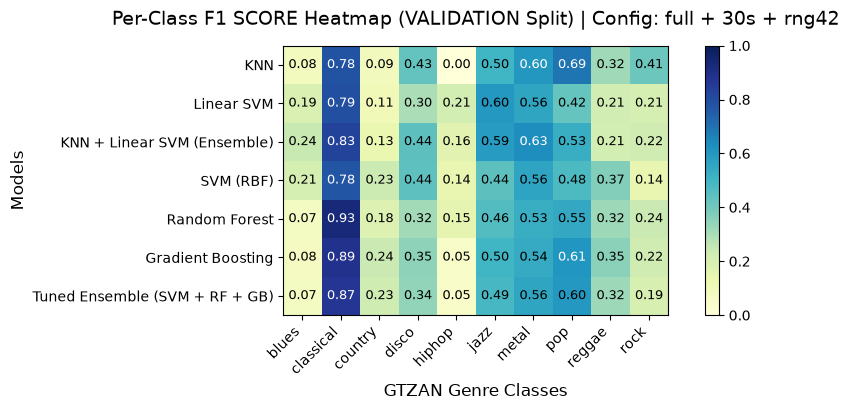

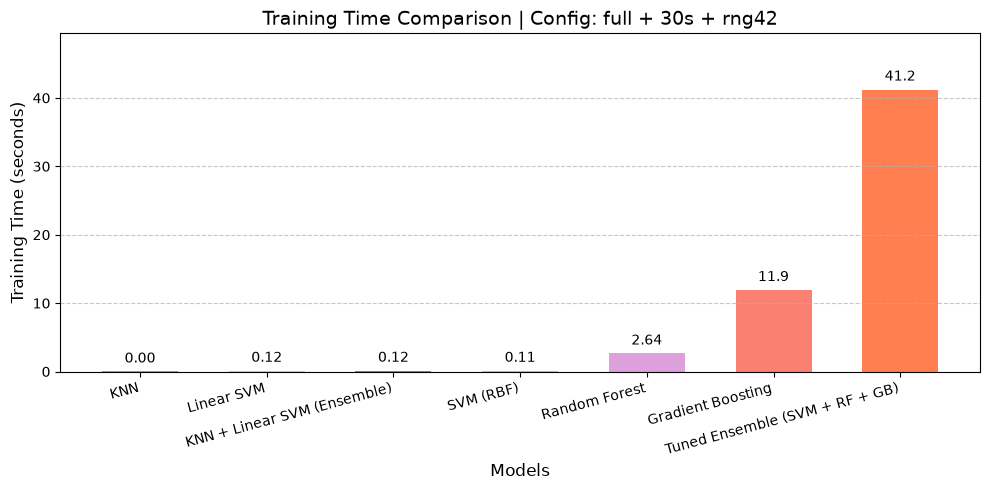

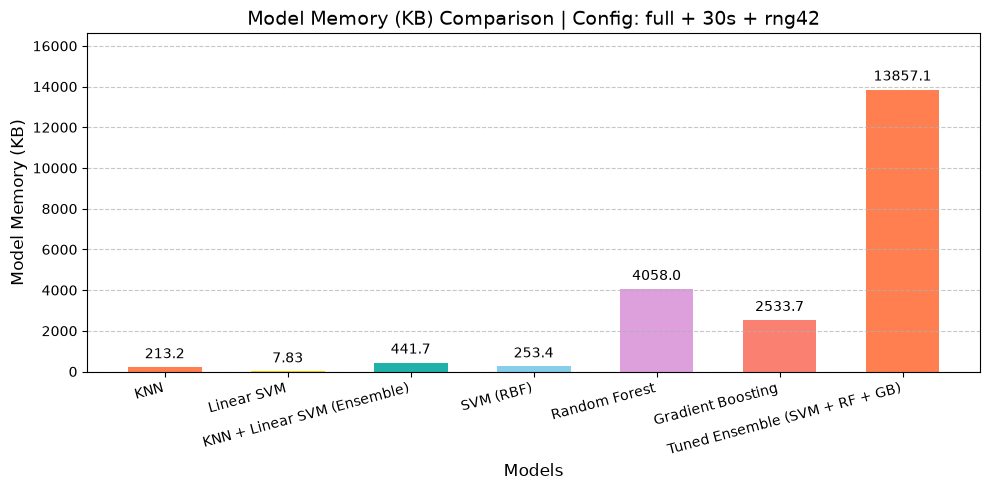

(<Figure size 1000x500 with 1 Axes>,
 <Axes: title={'center': 'Model Memory (KB) Comparison | Config: full + 30s + rng42'}, xlabel='Models', ylabel='Model Memory (KB)'>)

In [23]:
classifers['30s_full_rng42'].plot_per_class_heatmap(
    metric_key='f1 score', data_split='val', displayPlot=True)
classifers['30s_full_rng42'].plot_resource_comparison(
    metric='train time', displayPlot=True)
classifers['30s_full_rng42'].plot_resource_comparison(
    metric='model memory', displayPlot=True)
# classifers['3s_full_rng42'].plot_resource_comparison(
#     metric='file size', memory_unit='MB', displayPlot=True)

In [24]:
def plot_metric_comparison_from_classifiers(classifiers_dict, metric='Macro F1-Score', data_split='test'):
    """
    Plots a grouped bar chart comparing all models across configurations 
    by calling each classifier's built-in plot_metric_comparison logic 
    (or extracting the metrics on the fly).
    """
    master_records = []

    # 1. Loop through all trained classifiers in your dictionary
    for config_name, clf in classifiers_dict.items():
        # Determine the target data split for the class method
        _,_, y_true, X_data = clf._parse_dataset_type(dataset_split)
        # print(X_data.columns)

        if y_true is None or X_data is None:
            continue  # Skip if data isn't loaded for this classifier

        # 2. Iterate through models inside this classifier instance
        for model_name, model_dict in clf.models.items():
            estimator = model_dict.get('model') if isinstance(model_dict, dict) else model_dict
            if estimator is None:
                continue

            # Generate predictions using the class's own predict method
            y_pred = clf.predict(X_data, target_model=model_name)

            # Compute metrics dynamically using the same logic as your class method
            acc = accuracy_score(y_true, y_pred)
            bal_acc = balanced_accuracy_score(y_true, y_pred)
            error = 1.0 - acc
            prec, rec, f1, _ = precision_recall_fscore_support(
                y_true, y_pred, average='macro', zero_division=0
            )

            master_records.append({
                'Configuration': config_name,
                'Model': model_name,
                'Error': error,
                'Balanced Accuracy': bal_acc,
                'Accuracy': acc,
                'Macro F1-Score': f1,
                'Precision': prec,
                'Recall': rec
            })

    # 3. Convert records into a master DataFrame
    if not master_records:
        raise ValueError("No valid model metrics were found across the provided classifiers dictionary.")
    
    df_master = pd.DataFrame(master_records)

    # 4. Pivot data so models become columns and configurations become rows
    # (Matches your original grouping structure)
    df_pivot = df_master.pivot(index='Configuration', columns='Model', values=metric)

    # 5. Plotting
    fig, ax = plt.subplots(figsize=(12, 6))
    df_pivot.plot(kind='bar', ax=ax, width=0.8, colormap='tab10')

    ax.set_title(f'{metric} Comparison Across All Configurations ({data_split.capitalize()} Split)', fontsize=14)
    ax.set_xlabel('Dataset & Feature Configuration', fontsize=12)
    ax.set_ylabel(metric, fontsize=12)
    
    # Set y-limits automatically based on metric type
    metric_lower = metric.lower()
    if any(term in metric_lower for term in ['error', 'accuracy', 'balanced', 'f1', 'precision', 'recall', 'score']):
        ax.set_ylim(0, 1.05)
        
    plt.xticks(rotation=30, ha='right')
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.legend(loc='best')

    plt.tight_layout()
    plt.show()
    
    return fig, ax, df_master

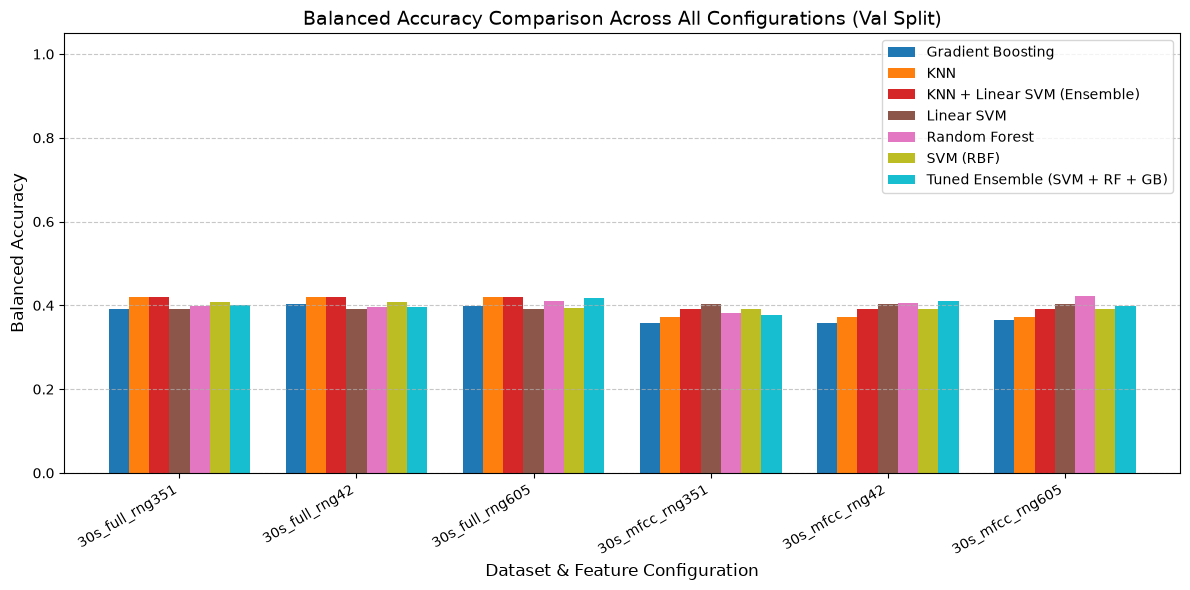

In [25]:
_, _, val_df = plot_metric_comparison_from_classifiers(
    classifiers_dict=classifers, 
    metric='Balanced Accuracy', 
    data_split='val'
)

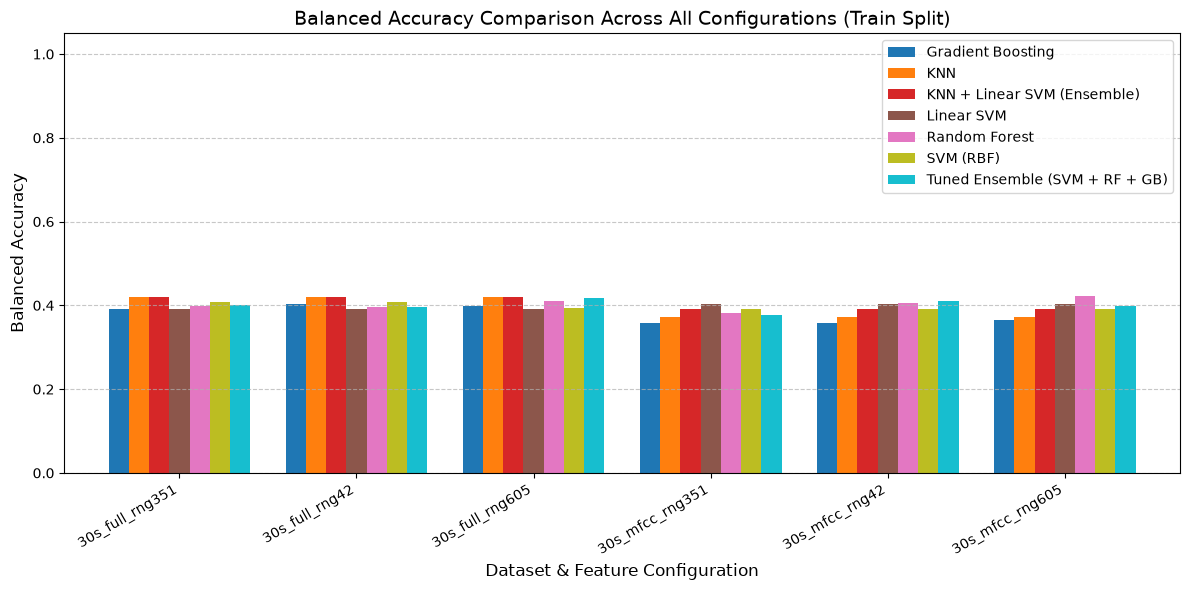

In [26]:
_, _, train_df = plot_metric_comparison_from_classifiers(
    classifiers_dict=classifers, 
    metric='Balanced Accuracy', 
    data_split='train'
)

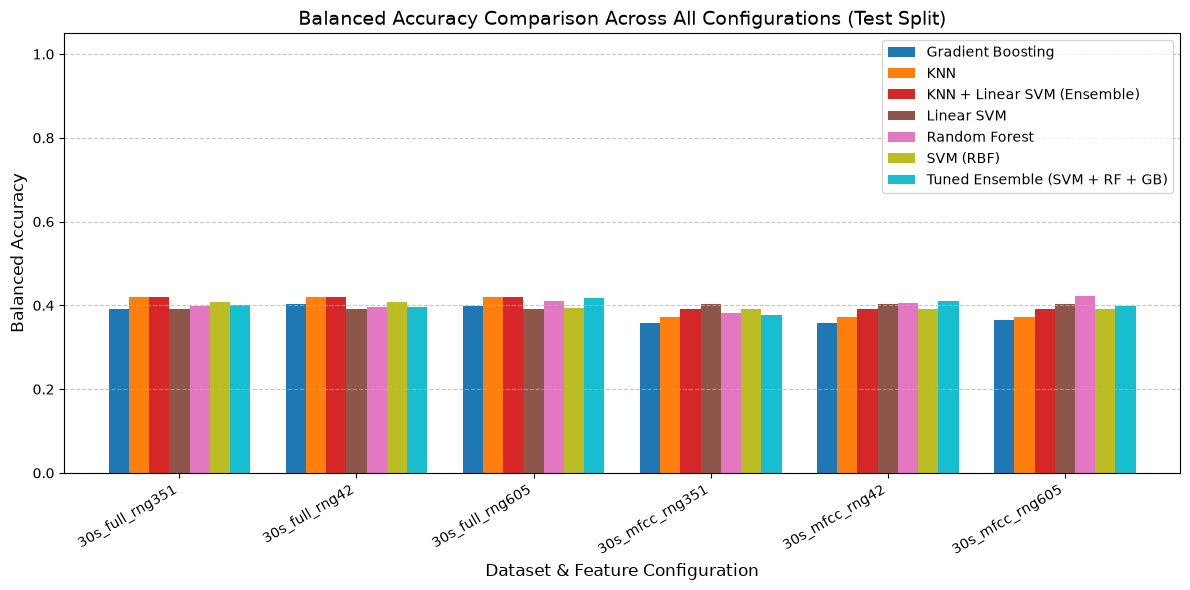

In [27]:
_, _, test_df = plot_metric_comparison_from_classifiers(
    classifiers_dict=classifers, 
    metric='Balanced Accuracy', 
    data_split='test'
)

In [28]:
print('='*30 + 'Training Dataset Metrics')
print(train_df.to_string())

print('\n' + '='*30 + 'Validation Dataset Metrics')
print(val_df.to_string())

print('\n' + '='*30 + 'Testing Dataset Metrics')
print(test_df.to_string())

==============================Training Dataset Metrics
      Configuration                           Model     Error  Balanced Accuracy  Accuracy  Macro F1-Score  Precision    Recall
0    30s_full_rng42                             KNN  0.596059           0.420803  0.403941        0.390964   0.481551  0.420803
1    30s_full_rng42                      Linear SVM  0.635468           0.390817  0.364532        0.358985   0.365767  0.390817
2    30s_full_rng42     KNN + Linear SVM (Ensemble)  0.586207           0.418992  0.413793        0.398249   0.565480  0.418992
3    30s_full_rng42                       SVM (RBF)  0.600985           0.408971  0.399015        0.378266   0.416418  0.408971
4    30s_full_rng42                   Random Forest  0.620690           0.396419  0.379310        0.373985   0.394215  0.396419
5    30s_full_rng42               Gradient Boosting  0.610837           0.403846  0.389163        0.382388   0.405317  0.403846
6    30s_full_rng42  Tuned Ensemble (SVM + RF + G

In [29]:
from sklearn.dummy import DummyClassifier
X_train_full = classifers['30s_full_rng42'].X_train
y_train_full = classifers['30s_full_rng42'].y_train
X_val_full = classifers['30s_full_rng42'].X_val
y_val_full = classifers['30s_full_rng42'].y_val

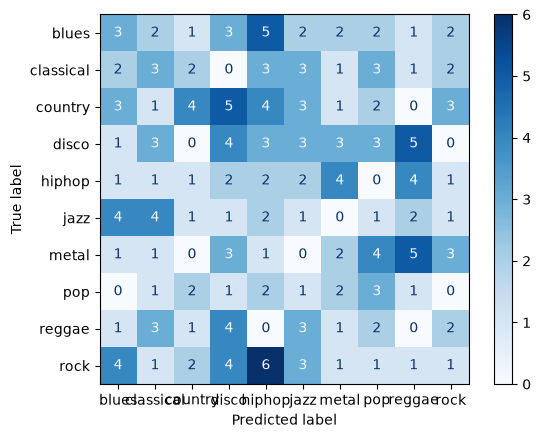

In [30]:
dum = DummyClassifier(strategy='stratified')
dum.fit(X_train_full,y_train_full)
dum_pred = dum.predict(X_val_full)
cm = ConfusionMatrixDisplay.from_predictions(
    y_val_full,
    dum_pred,
    cmap=plt.cm.Blues                       ,
    labels=classifers['30s_full_rng42'].labels)
plt.show()

In [31]:
print(classification_report(y_val_full,dum_pred,labels=classifers['30s_full_rng42'].labels))

              precision    recall  f1-score   support

       blues       0.15      0.13      0.14        23
   classical       0.15      0.15      0.15        20
     country       0.29      0.15      0.20        26
       disco       0.15      0.16      0.15        25
      hiphop       0.07      0.11      0.09        18
        jazz       0.05      0.06      0.05        17
       metal       0.12      0.10      0.11        20
         pop       0.14      0.23      0.18        13
      reggae       0.00      0.00      0.00        17
        rock       0.07      0.04      0.05        24

    accuracy                           0.11       203
   macro avg       0.12      0.11      0.11       203
weighted avg       0.13      0.11      0.12       203



In [32]:
classifers['30s_full_rng351']